# Time Series: Advanced Assignment Part 1
## Using Facebook Prophet for forecasting
Student Name: Cleo Joe Rheikel Sinuhaji, Federico Casarin

Group No: 15

In this assignment you will work with facebook prohet algorithm. We need two datasets for this assignmnet both are provided via canvas. 

## Basic Exercise

In [1]:
# Load packages
import pandas as pd # for data manipulation
import numpy as np # numerical work
import matplotlib.pyplot as plt # plotting
import datetime as dt # for date time
import prophet as ph # for prophet

Importing plotly failed. Interactive plots will not work.


In [2]:
# Read_data
# Importing data
df = pd.read_csv('elec_vict.csv',
                infer_datetime_format=True, 
                na_values=['nan','?'])
df.head()

/var/folders/45/82jzbv_s5pj342pnp3q6xmhh0000gn/T/ipykernel_73040/2829620089.py:3: FutureWarning: The argument 'infer_datetime_format' is deprecated and will be removed in a future version. A strict version of it is now the default, see https://pandas.pydata.org/pdeps/0004-consistent-to-datetime-parsing.html. You can safely remove this argument.
  df = pd.read_csv('elec_vict.csv',


,Time,Demand,Temperature,Date,Holiday
0,2011-12-31T13:00:00Z,4382.825174,21.40,2012-01-01,True
1,2011-12-31T13:30:00Z,4263.365526,21.05,2012-01-01,True
2,2011-12-31T14:00:00Z,4048.966046,20.70,2012-01-01,True
3,2011-12-31T14:30:00Z,3877.563330,20.55,2012-01-01,True
4,2011-12-31T15:00:00Z,4036.229746,20.40,2012-01-01,True


### Exercise 1: Data Visulization

In [3]:
df['Time'] = pd.to_datetime(df['Time'])
def remove_timezone(dt):
    return dt.replace(tzinfo=None)

df['Time'] = df['Time'].apply(remove_timezone)

df = df.set_index('Time')
df.head()


,Demand,Temperature,Date,Holiday
Time,,,,
2011-12-31 13:00:00,4382.825174,21.40,2012-01-01,True
2011-12-31 13:30:00,4263.365526,21.05,2012-01-01,True
2011-12-31 14:00:00,4048.966046,20.70,2012-01-01,True
2011-12-31 14:30:00,3877.563330,20.55,2012-01-01,True
2011-12-31 15:00:00,4036.229746,20.40,2012-01-01,True


In [4]:
df.index

DatetimeIndex(['2011-12-31 13:00:00', '2011-12-31 13:30:00',
               '2011-12-31 14:00:00', '2011-12-31 14:30:00',
               '2011-12-31 15:00:00', '2011-12-31 15:30:00',
               '2011-12-31 16:00:00', '2011-12-31 16:30:00',
               '2011-12-31 17:00:00', '2011-12-31 17:30:00',
               ...
               '2014-12-31 08:00:00', '2014-12-31 08:30:00',
               '2014-12-31 09:00:00', '2014-12-31 09:30:00',
               '2014-12-31 10:00:00', '2014-12-31 10:30:00',
               '2014-12-31 11:00:00', '2014-12-31 11:30:00',
               '2014-12-31 12:00:00', '2014-12-31 12:30:00'],
              dtype='datetime64[ns]', name='Time', length=52608, freq=None)

Text(0, 0.5, 'Temperature')

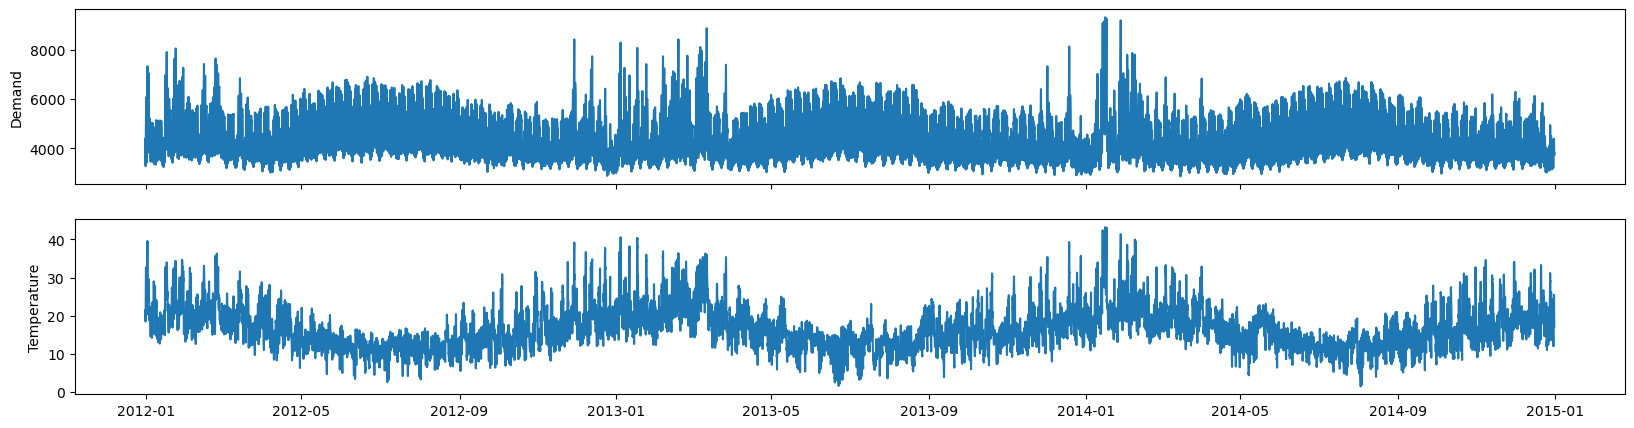

In [5]:
# Let us first plot demand and temprature (see output below)

fi, (ax1, ax2) = plt.subplots(2, 1, figsize=(20,5), sharex=True)
ax1.plot(df.index, df['Demand'])
ax1.set_ylabel("Demand")

ax2.plot(df.index, df['Temperature'])
ax2.set_ylabel("Temperature")


#write your code here


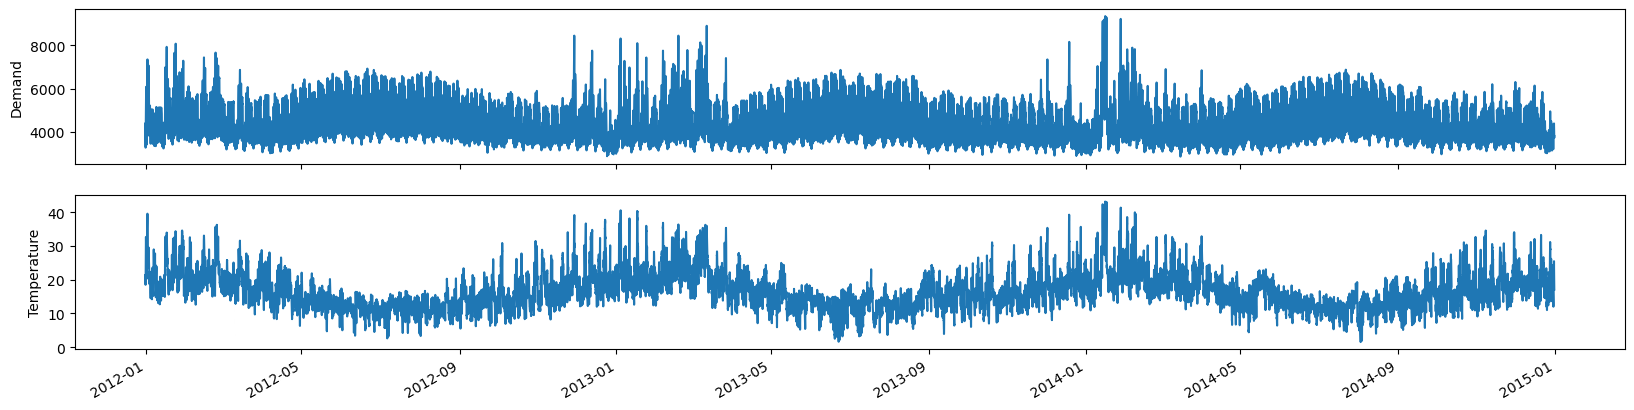

/var/folders/45/82jzbv_s5pj342pnp3q6xmhh0000gn/T/ipykernel_73040/888819254.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


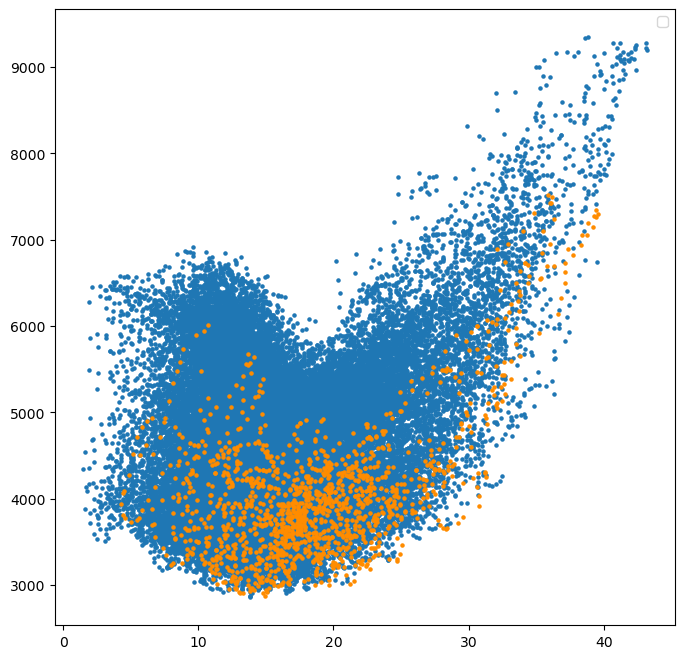

In [6]:
# Now plot temprature vs demand with Holiday (see example output below)
# Write your code here

fig, ax = plt.subplots(figsize=(8,8))
true_df= df[df['Holiday']]
false_df = df[df['Holiday'] == False]
ax.scatter(false_df['Temperature'], false_df['Demand'], s=5, )
ax.scatter(true_df['Temperature'], true_df['Demand'], s=5, c='darkorange')
ax.legend()
plt.show()


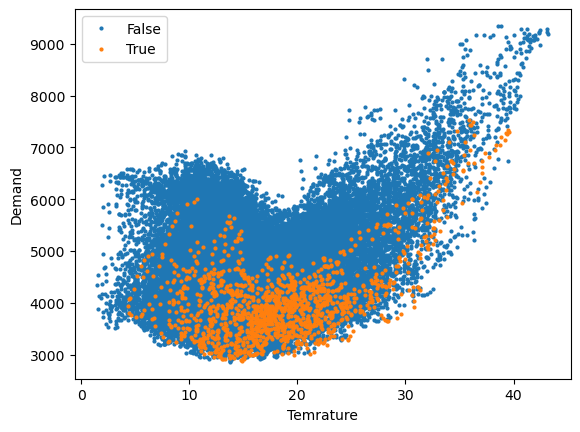

## Forecasting Using Facebook Prophet

In [7]:
# As a first step we create a time series acceptable for Prophet
ts=pd.DataFrame({'ds':df.index,'y':df.Demand})
ts.head()

,ds,y
Time,,
2011-12-31 13:00:00,2011-12-31 13:00:00,4382.825174
2011-12-31 13:30:00,2011-12-31 13:30:00,4263.365526
2011-12-31 14:00:00,2011-12-31 14:00:00,4048.966046
2011-12-31 14:30:00,2011-12-31 14:30:00,3877.563330
2011-12-31 15:00:00,2011-12-31 15:00:00,4036.229746


In [8]:
# We start by invoking Prophet 
prophet=ph.Prophet(changepoint_prior_scale=0.01)
prophet.fit(ts)




/opt/homebrew/Caskroom/miniconda/base/envs/ml-env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
16:33:57 - cmdstanpy - INFO - Chain [1] start processing
16:34:01 - cmdstanpy - INFO - Chain [1] done processing


In [9]:
# create a future data frame 
# forecast for next 6 months, with freq='H'
# Write your code here
total_period = 6 * 30 * 24
future = prophet.make_future_dataframe(freq='h', periods=total_period)
forecast = prophet.predict(future)

In [10]:
# display the most critical output columns from the forecast
forecast[['ds','yhat','yhat_lower','yhat_upper']].head()



,ds,yhat,yhat_lower,yhat_upper
0,2011-12-31 13:00:00,3325.603601,2722.431229,3953.537718
1,2011-12-31 13:30:00,3265.737468,2618.275354,3911.803367
2,2011-12-31 14:00:00,3192.272639,2580.343321,3794.762346
3,2011-12-31 14:30:00,3093.667338,2465.640598,3752.907698
4,2011-12-31 15:00:00,2966.562980,2309.043784,3604.001838


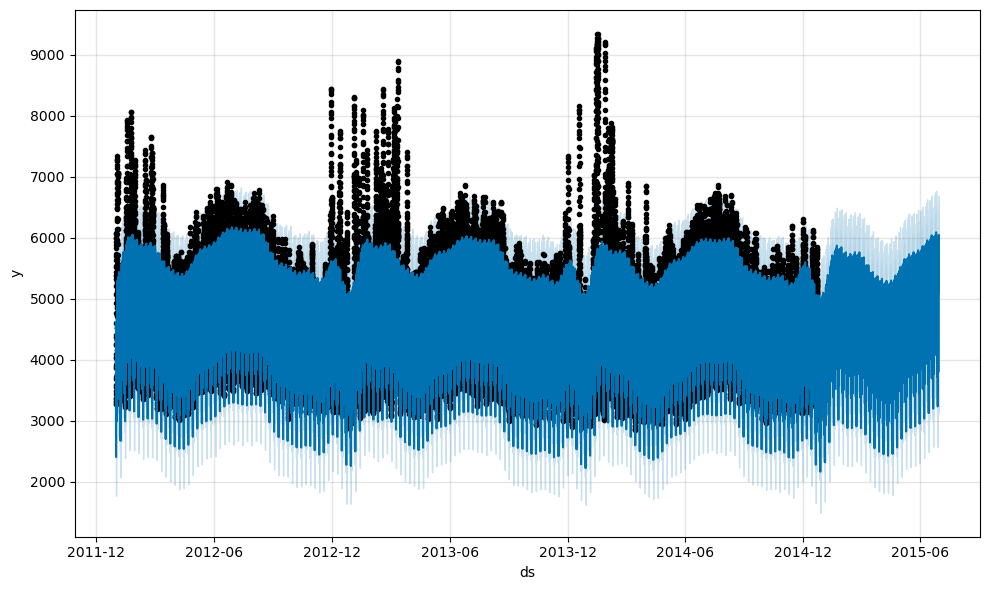

In [11]:
# plot the forecast
fig = prophet.plot(forecast)

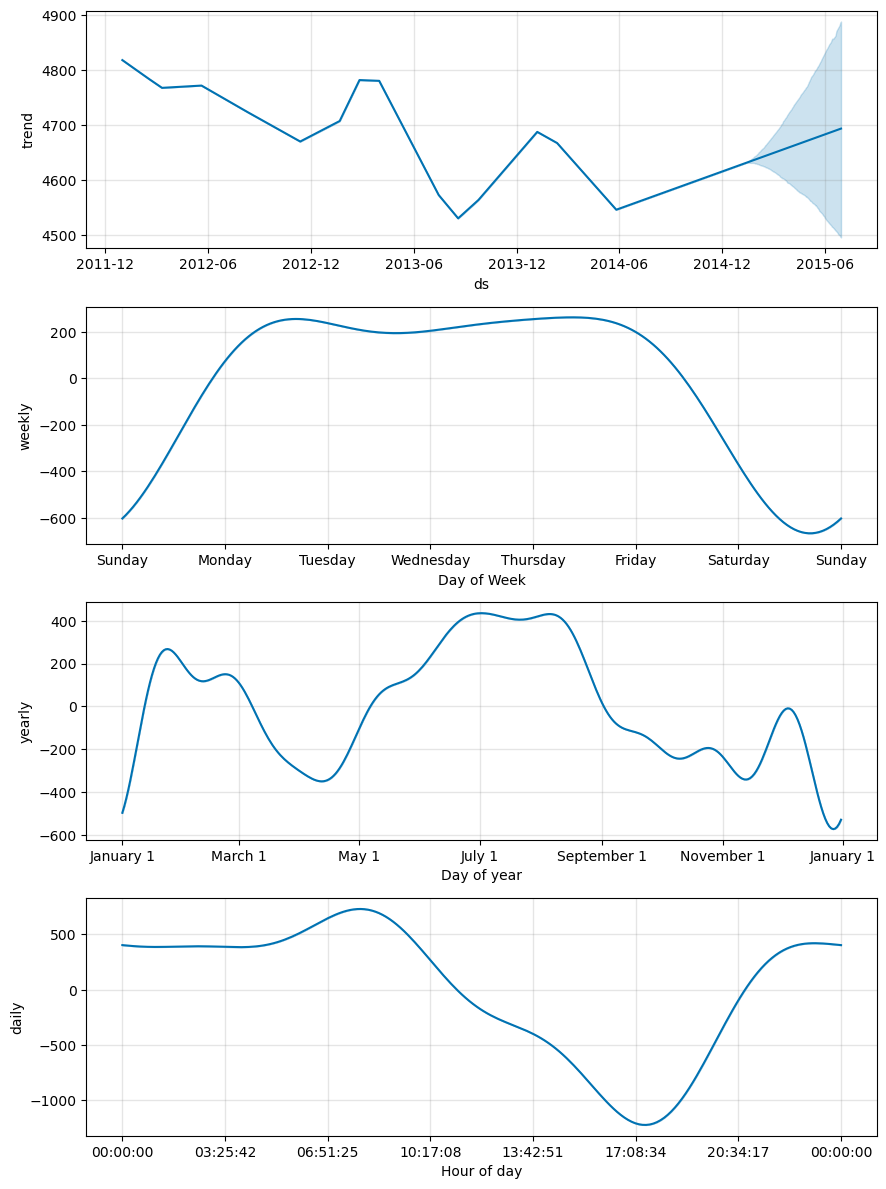

In [12]:
# Plot forecast components (example outpur given below)
fig2 = prophet.plot_components(forecast)

## Regular 

Consider the dataset uselec used for the basic exercise. You must have fit a ARIMA model to that dataset. Your exercise is to fit a prediction model using Prophet and compare the results. Your code can come down here. 

In [13]:
df_usmelec = pd.read_csv("../basic/usmelec.csv")
df_usmelec.head()

,index,value
0,1973 Jan,160.218
1,1973 Feb,143.539
2,1973 Mar,148.158
3,1973 Apr,139.589
4,1973 May,147.395


In [14]:
df_usmelec['index'] = pd.to_datetime(df_usmelec['index'], format='mixed')
df_usmelec.head()

,index,value
0,1973-01-01,160.218
1,1973-02-01,143.539
2,1973-03-01,148.158
3,1973-04-01,139.589
4,1973-05-01,147.395


In [15]:

ts2 = pd.DataFrame({'ds': df_usmelec['index'], 'y': df_usmelec['value']})
ts2.head()   


,ds,y
0,1973-01-01,160.218
1,1973-02-01,143.539
2,1973-03-01,148.158
3,1973-04-01,139.589
4,1973-05-01,147.395


In [16]:
prophet2 = ph.Prophet(changepoint_prior_scale=0.1)
prophet2.fit(ts2)


16:34:06 - cmdstanpy - INFO - Chain [1] start processing
16:34:06 - cmdstanpy - INFO - Chain [1] done processing


In [ ]:
h = 15 * 12 # 15-year horizon, same as the ARIMA forecast

future2 = prophet2.make_future_dataframe(periods=h, freq='MS')
forecast2 = prophet2.predict(future2)

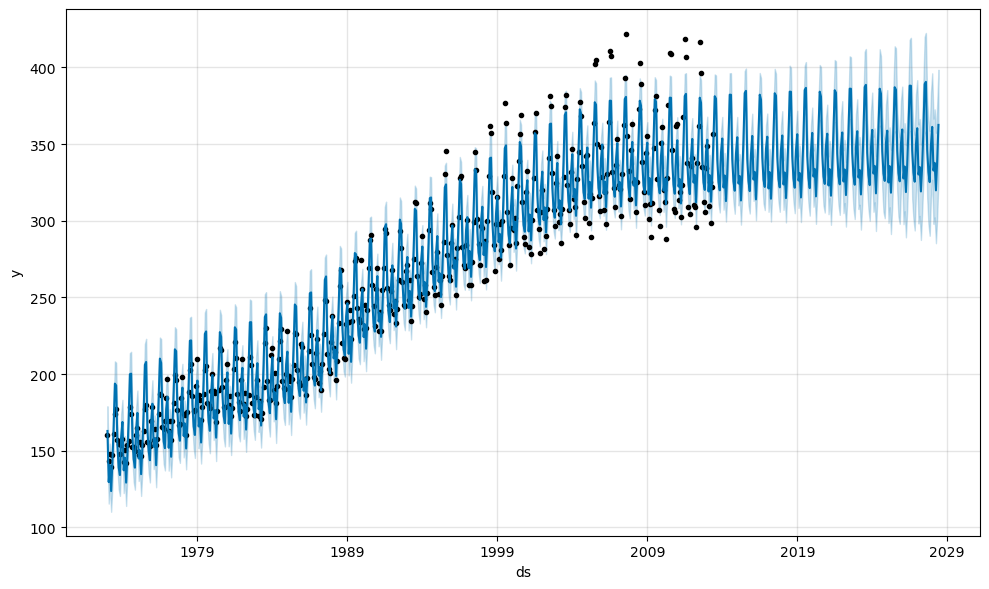

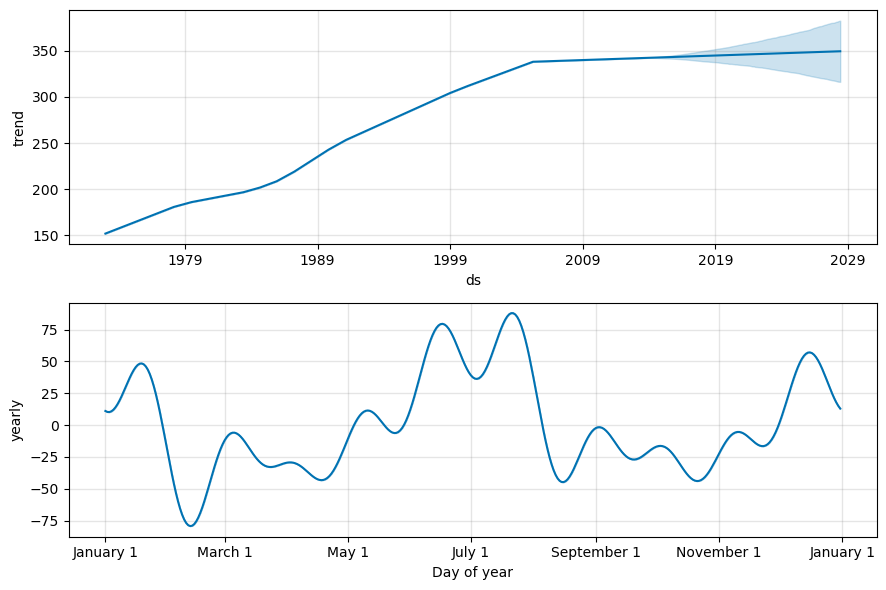

In [18]:
fig1 = prophet2.plot(forecast2)
fig2 = prophet2.plot_components(forecast2)

### ARIMA Model


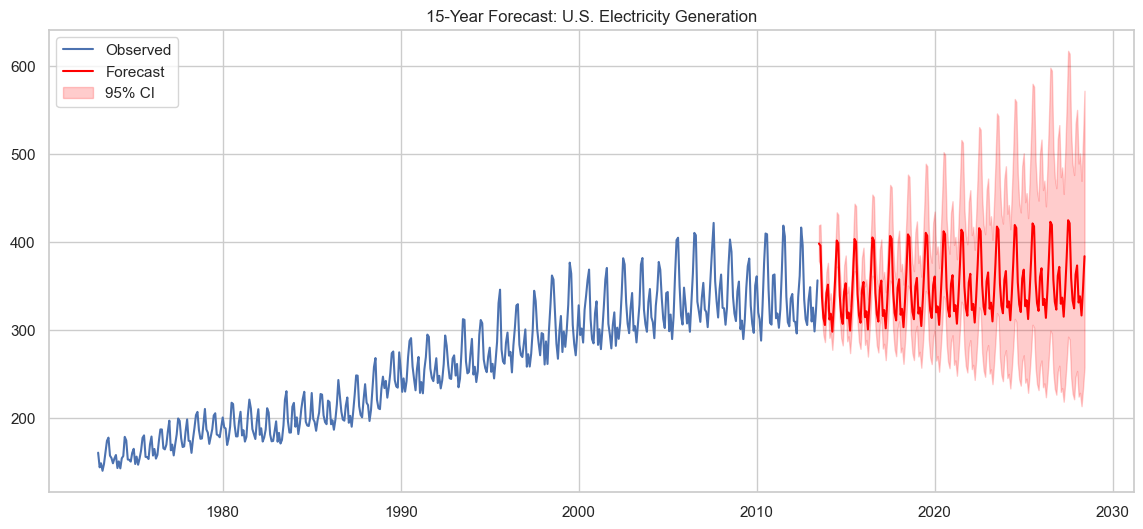

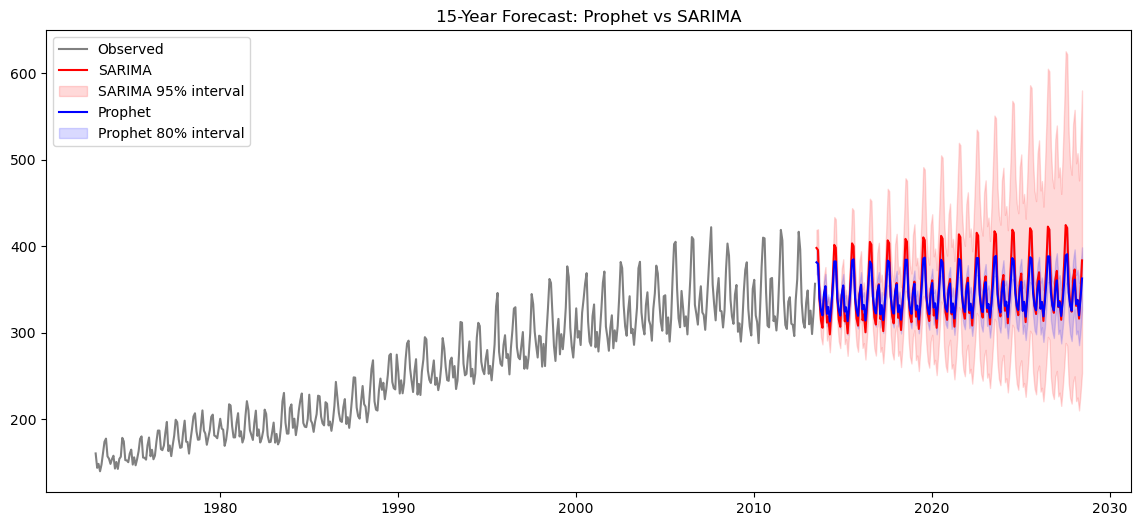

Forecast for May 2026 - SARIMA: 343.1, Prophet: 336.1


In [22]:
from statsmodels.tsa.arima.model import ARIMA

y2 = ts2.set_index('ds')['y'].asfreq('MS')
sarima = ARIMA(np.log(y2), order=(2, 1, 4), seasonal_order=(0, 1, 1, 12)).fit(method_kwargs={'maxiter': 500})

sarima_fc = sarima.get_forecast(steps=h)
sarima_mean = np.exp(sarima_fc.predicted_mean) # back-transform from log scale
sarima_ci = np.exp(sarima_fc.conf_int(alpha=0.05))

prophet_fc = forecast2.set_index('ds').iloc[-h:]

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(y2.index, y2, color='grey', label='Observed')
ax.plot(sarima_mean.index, sarima_mean, color='red', label='SARIMA')
ax.fill_between(sarima_mean.index, sarima_ci.iloc[:, 0], sarima_ci.iloc[:, 1], color='red', alpha=0.15, label='SARIMA 95% interval')
ax.plot(prophet_fc.index, prophet_fc['yhat'], color='blue', label='Prophet')
ax.fill_between(prophet_fc.index, prophet_fc['yhat_lower'], prophet_fc['yhat_upper'], color='blue', alpha=0.15, label='Prophet 80% interval')
ax.set_title("15-Year Forecast: Prophet vs SARIMA")
ax.legend(loc='upper left')
plt.show()

print("Forecast for May 2026 - SARIMA: %.1f, Prophet: %.1f" % (sarima_mean['2026-05-01'], prophet_fc.loc['2026-05-01', 'yhat']))

In [24]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

rows = []
for n_test in [24, 60]: # last 2 and 5 years for testing
    train, test = ts2.iloc[:-n_test], ts2.iloc[-n_test:]

    prophet_ho = ph.Prophet(changepoint_prior_scale=0.1)
    prophet_ho.fit(train)
    future_ho = prophet_ho.make_future_dataframe(periods=n_test, freq='MS')
    pred_prophet = prophet_ho.predict(future_ho)['yhat'].iloc[-n_test:].values

    sarima_ho = ARIMA(np.log(y2.iloc[:-n_test]), order=(2, 1, 4), seasonal_order=(0, 1, 1, 12)).fit(method_kwargs={'maxiter': 500})
    pred_sarima = np.exp(sarima_ho.forecast(n_test)).values

    for name, pred in {'Prophet': pred_prophet, 'SARIMA': pred_sarima}.items():
        rows.append({'Test months': n_test, 'Model': name,
                     'RMSE': np.sqrt(mean_squared_error(test['y'], pred)),
                     'MAE': mean_absolute_error(test['y'], pred),
                     'MAPE (%)': np.mean(np.abs((test['y'].values - pred) / test['y'].values)) * 100})

pd.DataFrame(rows).round(2)

16:41:46 - cmdstanpy - INFO - Chain [1] start processing
16:41:46 - cmdstanpy - INFO - Chain [1] done processing
16:41:52 - cmdstanpy - INFO - Chain [1] start processing
16:41:52 - cmdstanpy - INFO - Chain [1] done processing


,Test months,Model,RMSE,MAE,MAPE (%)
0,24,Prophet,19.31,17.33,5.18
1,24,SARIMA,12.69,11.76,3.50
2,60,Prophet,29.30,25.92,8.06
3,60,SARIMA,30.12,27.72,8.38


### Comparison of Prophet and SARIMA

The SARIMA model is the one from the previous assignment, SARIMA(2,1,4)(0,1,1,12) fitted on the log of the series. Prophet is fitted on the raw series with `changepoint_prior_scale=0.1`.

**15-year forecast.** Both models continue the yearly pattern with a summer and a winter peak, but they differ in several ways. SARIMA forecasts a higher level than Prophet. In the last forecast year the average is about 359 for SARIMA and 349 for Prophet. Secondly, Prophet's seasonality is additive, so it is one average pattern over the whole 40 years (peak to trough about 70). This is too small for recent years, where the swing is above 100, so Prophet underestimates the summer peaks. SARIMA works on the log scale, so its seasonal swing scales with the level (about 100). Lastly, the two interval levels are not the same. Prophet's interval mainly reflects uncertainty in the trend, so it looks too confident for a forecast.

As a check with the EIA figure used in the previous assignment (May 2026: 354.7), SARIMA forecasts 343.1 (3.3% too low) and Prophet 336.1 (5.2% too low).

SARIMA gives the more accurate short-term forecast and more realistic uncertainty for this series, but needed more work. Prophet is quick to fit and gives readable trend and seasonal components, but with the default additive seasonality it misses the growing seasonal swing.